# Weather Trend Forecasting
## Notebook 02: Exploratory Data Analysis

Input: `data/processed/weather_clean.csv` from notebook 01 (185 locations, one row per location per day).

Questions:
1. Where are the locations, and how does temperature change with latitude?
2. Why a single global average temperature is misleading
3. What the six forecasting cities look like over time
4. How much the snapshot hour matters
5. Precipitation: how often it rains, where, and when
6. How the weather variables relate to each other
7. Which weather conditions are most common

Every figure is saved to `reports/figures/` with the prefix `02_`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FIG = Path('../reports/figures')
pd.set_option('display.width', 160)
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold',
})
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
BLUE, ORANGE, AQUA = PALETTE[:3]
CITIES = ['Moscow', 'London', 'New Delhi', 'Singapore', 'Canberra', 'Buenos Aires']

def save(fig, name):
    fig.savefig(FIG / name)
    print('saved', FIG / name)

In [2]:
df = pd.read_csv('../data/processed/weather_clean.csv', parse_dates=['date', 'time_utc', 'time_local'])
df['month'] = df['date'].dt.month
df['year_month'] = df['date'].dt.to_period('M')
print(df.shape)
print('locations:', df.groupby(['country', 'location_name']).ngroups, '| period:', df['date'].min().date(), 'to', df['date'].max().date())
df[['temperature_celsius', 'precip_mm', 'humidity', 'wind_kph', 'pressure_mb', 'cloud', 'uv_index']].describe().round(2)

(161561, 40)
locations: 185 | period: 2024-05-16 to 2026-10-13


,temperature_celsius,precip_mm,humidity,wind_kph,pressure_mb,cloud,uv_index
count,161561.00,161561.00,161561.00,161561.00,161561.00,161561.00,161561.0
mean,21.46,0.13,66.62,12.72,1014.17,39.88,3.1
std,9.27,0.60,23.51,8.23,6.75,34.76,3.5
min,-29.80,0.00,2.00,3.60,964.00,0.00,0.0
25%,16.20,0.00,51.00,6.10,1010.00,0.00,0.0
50%,23.60,0.00,72.00,10.80,1014.00,27.00,1.5
75%,27.70,0.02,84.00,17.30,1018.00,75.00,5.9
max,49.20,74.52,100.00,81.00,1052.00,100.00,16.3


## 1. Locations and temperature by latitude

One point per location, coloured by its mean temperature over the whole period. There is no map
library in this project, so longitude and latitude are drawn as a plain scatter plot. The outline of the
continents is still visible from the capitals.

saved ../reports/figures/02_location_map.png


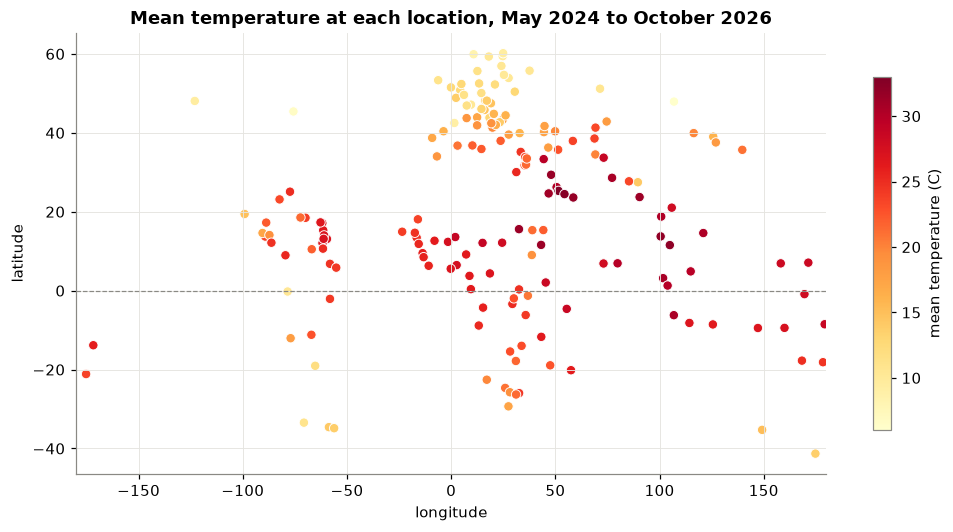

In [3]:
loc = (df.groupby(['country', 'location_name'])
         .agg(lat=('latitude', 'mean'), lon=('longitude', 'mean'), continent=('continent', 'first'),
              mean_temp=('temperature_celsius', 'mean'), days=('date', 'size'))
         .reset_index())

fig, ax = plt.subplots(figsize=(11, 5.2))
sc = ax.scatter(loc['lon'], loc['lat'], c=loc['mean_temp'], cmap='YlOrRd', s=38,
                edgecolor='white', linewidth=0.6)
ax.axhline(0, color='#8a8984', linewidth=0.8, linestyle='--')
ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
ax.set_xlim(-180, 180)
ax.set_title('Mean temperature at each location, May 2024 to October 2026')
fig.colorbar(sc, ax=ax, label='mean temperature (C)', shrink=0.8)
save(fig, '02_location_map.png')
plt.show()

In [4]:
print('hottest locations on average:')
print(loc.nlargest(5, 'mean_temp')[['country', 'location_name', 'mean_temp']].round(1).to_string(index=False))
print()
print('coldest locations on average:')
print(loc.nsmallest(5, 'mean_temp')[['country', 'location_name', 'mean_temp']].round(1).to_string(index=False))

hottest locations on average:
             country location_name  mean_temp
               Qatar          Doha       33.0
United Arab Emirates     Abu Dhabi       32.5
            Cambodia    Phnom Penh       32.1
            Thailand       Bangkok       31.9
                Oman        Muscat       31.8

coldest locations on average:
                 country     location_name  mean_temp
                Mongolia       Ulaanbaatar        6.0
                  Canada            Ottawa        6.6
                  Norway              Oslo        8.4
                 Andorra  Andorra La Vella        9.0
United States of America Washington Harbor        9.3


The seasonal range of a location is measured here as the difference between its warmest and coldest calendar
month (average temperature of that month over all years).

saved ../reports/figures/02_temperature_vs_latitude.png


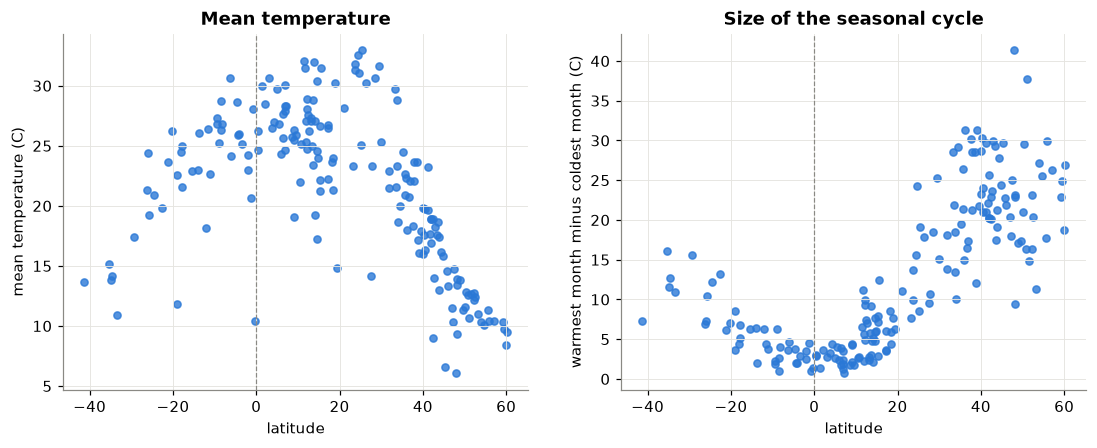

correlation of mean temperature with |latitude|: -0.76
correlation of seasonal range with |latitude|:  0.85


In [5]:
clim = df.groupby(['country', 'location_name', 'month'])['temperature_celsius'].mean()
season_range = (clim.groupby(level=[0, 1]).max() - clim.groupby(level=[0, 1]).min()).rename('season_range')
loc = loc.join(season_range, on=['country', 'location_name'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(loc['lat'], loc['mean_temp'], s=22, color=BLUE, alpha=0.8)
axes[0].set_xlabel('latitude')
axes[0].set_ylabel('mean temperature (C)')
axes[0].set_title('Mean temperature')
axes[1].scatter(loc['lat'], loc['season_range'], s=22, color=BLUE, alpha=0.8)
axes[1].set_xlabel('latitude')
axes[1].set_ylabel('warmest month minus coldest month (C)')
axes[1].set_title('Size of the seasonal cycle')
for ax in axes:
    ax.axvline(0, color='#8a8984', linewidth=0.8, linestyle='--')
save(fig, '02_temperature_vs_latitude.png')
plt.show()

print('correlation of mean temperature with |latitude|:', round(loc['mean_temp'].corr(loc['lat'].abs()), 2))
print('correlation of seasonal range with |latitude|: ', round(loc['season_range'].corr(loc['lat'].abs()), 2))

saved ../reports/figures/02_temperature_by_continent.png


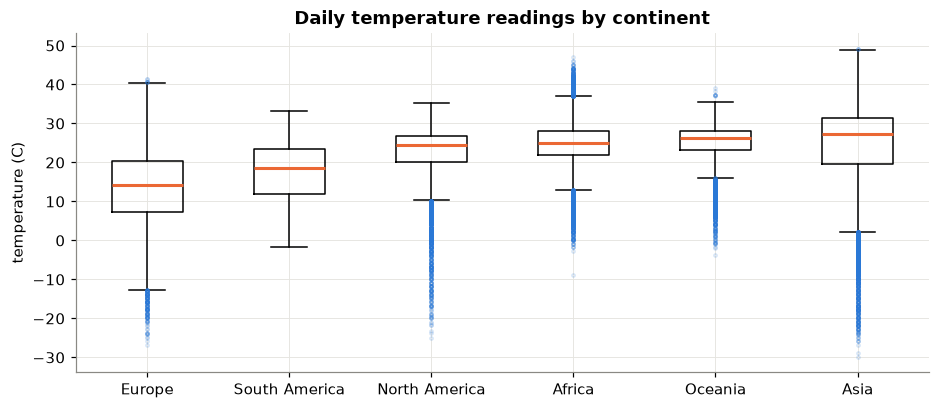

,mean,std,min,50%,max
continent,,,,,
Europe,14.0,9.5,-26.9,14.1,41.4
South America,17.9,6.5,-1.7,18.6,33.3
North America,22.4,6.7,-25.0,24.4,35.3
Africa,24.7,5.3,-8.8,25.1,47.1
Oceania,24.6,5.6,-3.7,26.3,39.1
Asia,24.8,10.2,-29.8,27.2,49.2


In [6]:
order = df.groupby('continent')['temperature_celsius'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([df.loc[df['continent'] == c, 'temperature_celsius'] for c in order], tick_labels=order, widths=0.5,
           flierprops=dict(marker='o', markersize=2, alpha=0.2, markeredgecolor=BLUE),
           medianprops=dict(color=ORANGE, linewidth=2))
ax.set_ylabel('temperature (C)')
ax.set_title('Daily temperature readings by continent')
save(fig, '02_temperature_by_continent.png')
plt.show()
df.groupby('continent')['temperature_celsius'].describe()[['mean', 'std', 'min', '50%', 'max']].round(1).loc[order]

## 2. Why a global average temperature is misleading

The northern and southern hemispheres have opposite seasons. When they are averaged together, their cycles
partly cancel out. The global line below also leans towards the northern pattern, because most locations
in the dataset are in the north.

hemisphere
north    144
south     41
Name: locations, dtype: int64


saved ../reports/figures/02_hemisphere_monthly.png


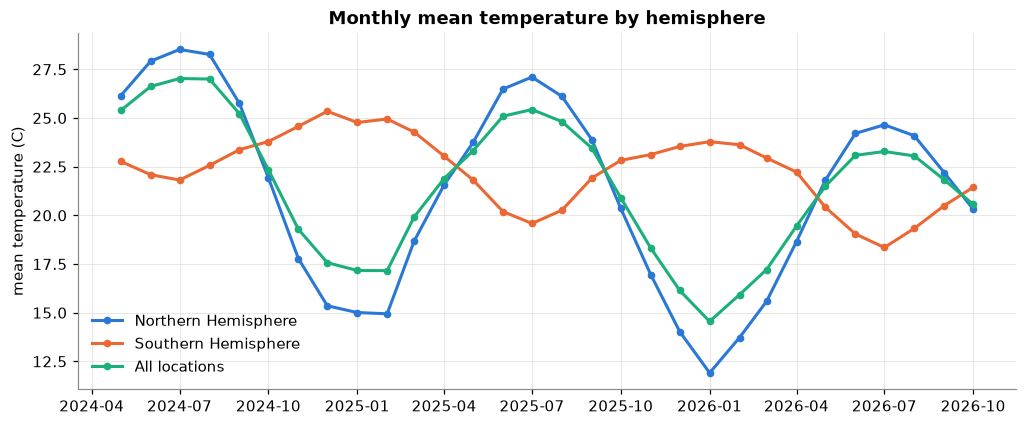

difference between warmest and coldest month:
hemisphere
north            16.6
south             7.0
all locations    12.5
dtype: float64

July mean temperature each year:
hemisphere  north  south  all locations
year_month                             
2024-07-01   28.5   21.8           27.0
2025-07-01   27.1   19.6           25.4
2026-07-01   24.7   18.3           23.3


In [7]:
print(df.groupby('hemisphere')['location_name'].nunique().rename('locations'))

monthly = df.groupby(['year_month', 'hemisphere'])['temperature_celsius'].mean().unstack()
monthly['all locations'] = df.groupby('year_month')['temperature_celsius'].mean()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.2))
for color, col, label in [(BLUE, 'north', 'Northern Hemisphere'), (ORANGE, 'south', 'Southern Hemisphere'),
                          (AQUA, 'all locations', 'All locations')]:
    ax.plot(monthly.index, monthly[col], color=color, linewidth=2, marker='o', markersize=4, label=label)
ax.set_ylabel('mean temperature (C)')
ax.set_title('Monthly mean temperature by hemisphere')
ax.legend(frameon=False, loc='lower left')
save(fig, '02_hemisphere_monthly.png')
plt.show()

swing = (monthly.max() - monthly.min()).round(1)
print('difference between warmest and coldest month:')
print(swing)
print()
print('July mean temperature each year:')
print(monthly[monthly.index.month == 7].round(1))

This is why the forecasting notebooks do not forecast a global average. They forecast six cities from
different climates and both hemispheres, where the seasonal cycle is visible and real.

## 3. The six forecasting cities

Daily readings (thin line) and a 30-day rolling mean (thick line). The rolling mean is only for display.

saved ../reports/figures/02_city_temperature.png


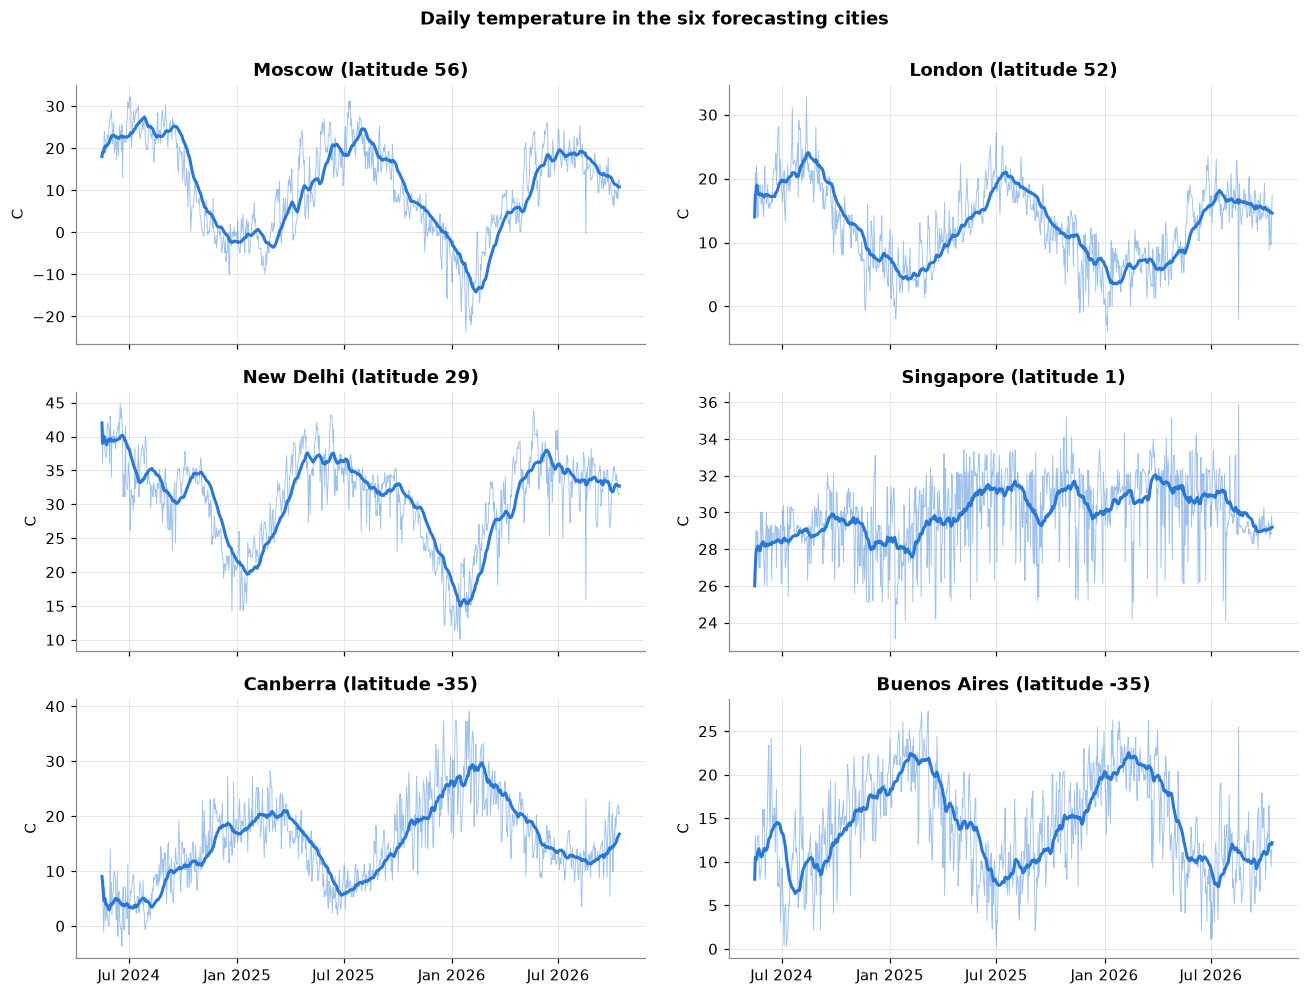

,mean,std,min,max
location_name,,,,
Moscow,10.4,11.1,-23.7,32.2
London,12.7,6.2,-4.0,32.8
New Delhi,30.7,6.7,10.1,44.8
Singapore,30.0,2.1,23.1,35.9
Canberra,15.2,7.5,-3.7,39.1
Buenos Aires,14.2,5.7,0.3,27.3


In [8]:
city = df[df['location_name'].isin(CITIES)].set_index('date').sort_index()

fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, name in zip(axes.flat, CITIES):
    s = city.loc[city['location_name'] == name, 'temperature_celsius']
    ax.plot(s.index, s.values, color=BLUE, linewidth=0.6, alpha=0.45)
    ax.plot(s.index, s.rolling('30D').mean(), color=BLUE, linewidth=2)
    ax.set_title(f"{name} (latitude {city.loc[city['location_name'] == name, 'latitude'].iloc[0]:.0f})")
    ax.set_ylabel('C')
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.suptitle('Daily temperature in the six forecasting cities', y=1.0, fontweight='bold')
fig.tight_layout()
save(fig, '02_city_temperature.png')
plt.show()

city.groupby('location_name')['temperature_celsius'].agg(['mean', 'std', 'min', 'max']).round(1).loc[CITIES]

### Same month, different years

Comparing the same calendar month across years is the simplest trend check. Remember the snapshot time drift
from notebook 01: the 2026 readings were taken about 6 hours earlier in the local day than the 2024 ones,
so a lower value in 2026 is not by itself evidence of a cooler year.

saved ../reports/figures/02_city_monthly_by_year.png


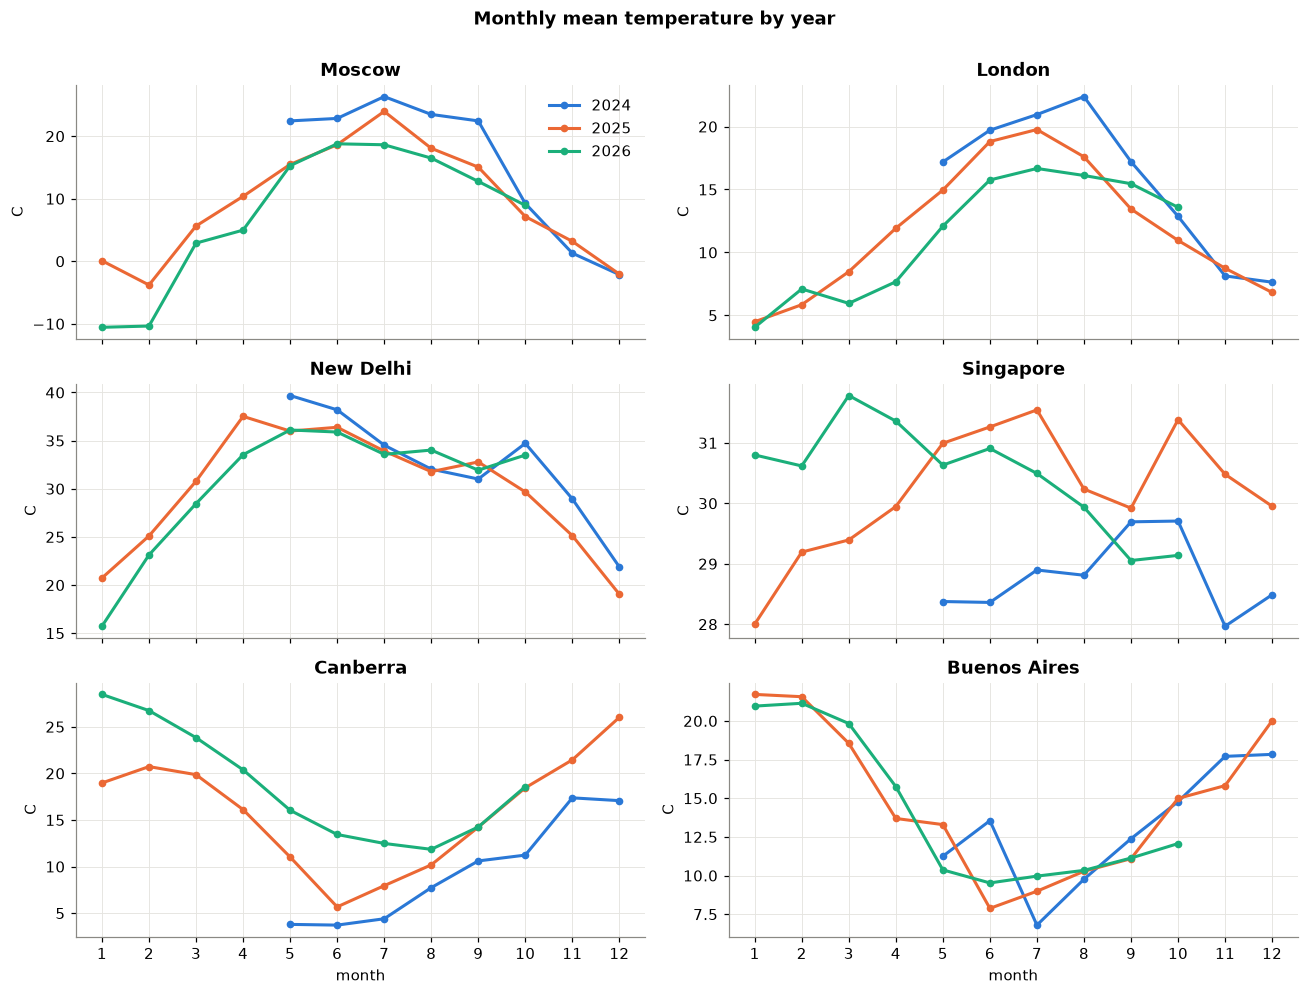

In [9]:
by_year = city.groupby(['location_name', city.index.year, city.index.month])['temperature_celsius'].mean()

fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, name in zip(axes.flat, CITIES):
    for color, year in zip([BLUE, ORANGE, AQUA], [2024, 2025, 2026]):
        s = by_year.loc[name, year]
        ax.plot(s.index, s.values, color=color, linewidth=2, marker='o', markersize=4, label=str(year))
    ax.set_title(name)
    ax.set_ylabel('C')
    ax.set_xticks(range(1, 13))
axes[0, 0].legend(frameon=False)
for ax in axes[-1]:
    ax.set_xlabel('month')
fig.suptitle('Monthly mean temperature by year', y=1.0, fontweight='bold')
fig.tight_layout()
save(fig, '02_city_monthly_by_year.png')
plt.show()

## 4. How much the snapshot hour matters

Notebook 01 showed that the snapshot moved about 6 hours earlier in the local day between 2024 and 2026.
The question is whether that is large enough to matter.

First, the UV index by local hour. UV is close to zero at night and peaks around 13:00, so the snapshot hour
decides whether a reading describes day or night conditions.

saved ../reports/figures/02_uv_by_local_hour.png


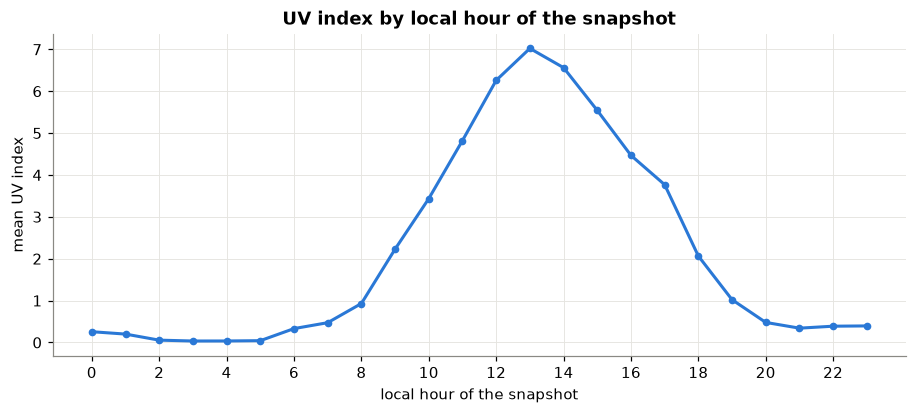

In [10]:
df['hour_bin'] = df['local_hour'].round().astype(int) % 24
uv_hour = df.groupby('hour_bin')['uv_index'].mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(uv_hour.index, uv_hour.values, color=BLUE, linewidth=2, marker='o', markersize=4)
ax.set_xlabel('local hour of the snapshot')
ax.set_ylabel('mean UV index')
ax.set_xticks(range(0, 24, 2))
ax.set_title('UV index by local hour of the snapshot')
save(fig, '02_uv_by_local_hour.png')
plt.show()

Next, can the effect of the hour on temperature be measured directly? Only if the hour varies while the season
stays the same. Within one location and one month it hardly varies, so the data cannot separate the hour effect
from the season.

In [11]:
hour_sd = df.groupby(['country', 'location_name', 'year_month'])['local_hour'].std()
print('spread of the snapshot hour within one location-month (std, hours):')
print('median', round(hour_sd.median(), 2), '| 90th percentile', round(hour_sd.quantile(0.9), 2))

spread of the snapshot hour within one location-month (std, hours):
median 0.22 | 90th percentile 0.59


What can be done is to put the hour shift next to the change in temperature between years, for the same
calendar months. Real year-to-year differences in a monthly mean are usually around 1 C. Larger differences,
in the direction the hour shift predicts, point to the clock rather than the climate.

In [12]:
med_hour = city.groupby(['location_name', city.index.year])['local_hour'].median().unstack()
yoy = by_year.unstack(1)
both = yoy.dropna(subset=[2024, 2025])
table = pd.DataFrame({
    'median hour 2024': med_hour[2024],
    'median hour 2025': med_hour[2025],
    'temp 2025 minus 2024 (C)': (both[2025] - both[2024]).groupby(level=0).mean(),
}).loc[CITIES].round(1)
table

,median hour 2024,median hour 2025,temp 2025 minus 2024 (C)
location_name,,,
Moscow,15.0,11.8,-3.3
London,13.0,9.8,-1.9
New Delhi,17.5,14.2,-2.0
Singapore,20.0,16.8,1.9
Canberra,21.5,18.8,4.9
Buenos Aires,9.0,5.8,-0.2


How to read this table: a snapshot that moves from the evening towards the afternoon should read warmer
(Canberra, Singapore). One that moves from the afternoon towards the morning should read colder (Moscow, London).
The large changes in those four cities follow that direction, and Buenos Aires (morning to early morning)
barely changes. New Delhi goes the other way: its snapshot moved closer to the afternoon peak but read colder, so
real weather differences between the years also play a part. The data cannot show how much of each difference
is the clock, so:
- `local_hour` is a feature in every forecasting model
- no conclusion about warming or cooling between years is drawn from this dataset

## 5. Precipitation

`precip_mm` is the precipitation reported at the moment of the snapshot, not a daily total. Most snapshots
have no rain, so the analysis looks at two things: how often it rains (share of snapshots with more than 0 mm)
and how much when it does.

In [13]:
wet = df['precip_mm'] > 0
print('share of snapshots with precipitation:', round(wet.mean() * 100, 1), '%')
print('amount when it rains (mm):')
print(df.loc[wet, 'precip_mm'].describe(percentiles=[0.5, 0.9, 0.99]).round(2))

share of snapshots with precipitation: 32.5 %
amount when it rains (mm):
count    52517.00
mean         0.40
std          0.99
min          0.01
50%          0.10
90%          1.07
99%          3.49
max         74.52
Name: precip_mm, dtype: float64


saved ../reports/figures/02_precipitation_overview.png


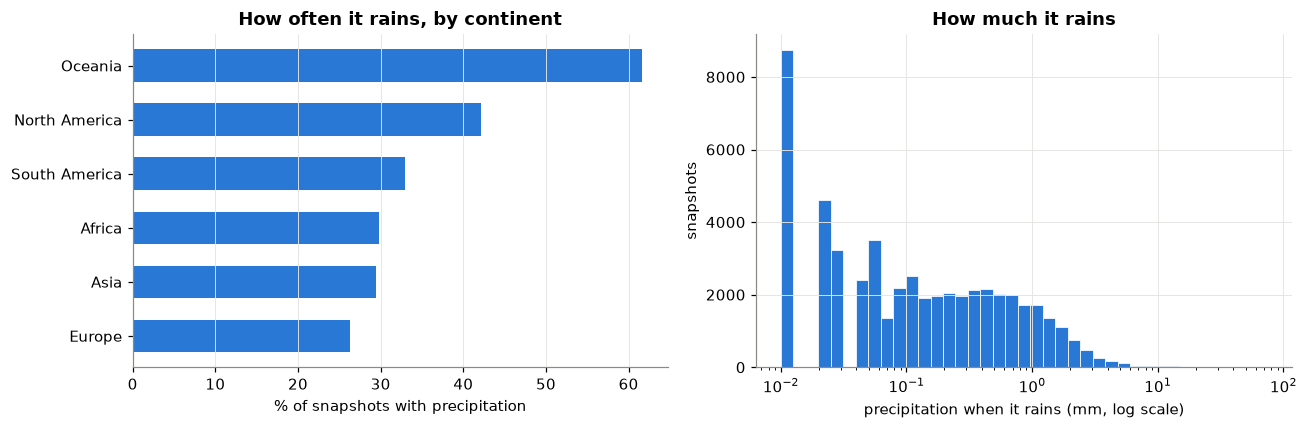

In [14]:
wet_share = wet.groupby(df['continent']).mean().sort_values() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(wet_share.index, wet_share.values, color=BLUE, height=0.6)
axes[0].set_xlabel('% of snapshots with precipitation')
axes[0].set_title('How often it rains, by continent')
axes[0].grid(axis='y', visible=False)
bins = np.logspace(np.log10(0.01), np.log10(df['precip_mm'].max()), 40)
axes[1].hist(df.loc[wet, 'precip_mm'], bins=bins, color=BLUE, edgecolor='white', linewidth=0.5)
axes[1].set_xscale('log')
axes[1].set_xlabel('precipitation when it rains (mm, log scale)')
axes[1].set_ylabel('snapshots')
axes[1].set_title('How much it rains')
fig.tight_layout()
save(fig, '02_precipitation_overview.png')
plt.show()

In [15]:
wettest = df.groupby(['country', 'location_name'])['precip_mm'].agg(share_wet=lambda s: (s > 0).mean() * 100, mean_mm='mean')
print('locations where it rains most often:')
wettest.sort_values('share_wet', ascending=False).head(8).round(2)

locations where it rains most often:


,,share_wet,mean_mm
country,location_name,,
Indonesia,Laos,85.81,0.57
Dominica,Roseau,83.60,0.12
Equatorial Guinea,Malabo,80.98,0.35
Samoa,Apia,80.94,0.29
Saint Lucia,Castries,79.11,0.14
Malaysia,Kuala Lumpur,79.00,0.58
Bhutan,Thimphu,78.63,0.32
Sri Lanka,Colombo,78.45,0.44


saved ../reports/figures/02_precipitation_city_month.png


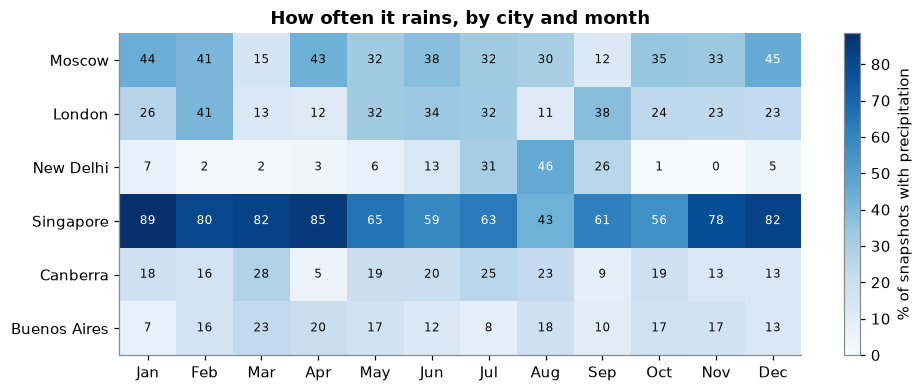

In [16]:
city_wet = (df[df['location_name'].isin(CITIES)]
            .assign(wet=lambda d: d['precip_mm'] > 0)
            .groupby(['location_name', 'month'])['wet'].mean().unstack().loc[CITIES] * 100)

fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(city_wet.values, cmap='Blues', aspect='auto', vmin=0)
ax.set_xticks(range(12), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_yticks(range(len(CITIES)), CITIES)
ax.grid(False)
for i in range(city_wet.shape[0]):
    for j in range(city_wet.shape[1]):
        v = city_wet.values[i, j]
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 45 else '#0b0b0b')
fig.colorbar(im, ax=ax, label='% of snapshots with precipitation')
ax.set_title('How often it rains, by city and month')
save(fig, '02_precipitation_city_month.png')
plt.show()

New Delhi shows the monsoon (July to September) clearly, and Singapore has rain in every month. The other
cities have weaker seasonal patterns in rain frequency.

## 6. Correlations between weather variables

Spearman (rank) correlation is used because precipitation, wind and visibility are skewed and not linear.
Correlations are computed over all locations and days, so part of them comes from differences between
climates, not only day-to-day weather.

saved ../reports/figures/02_correlation_heatmap.png


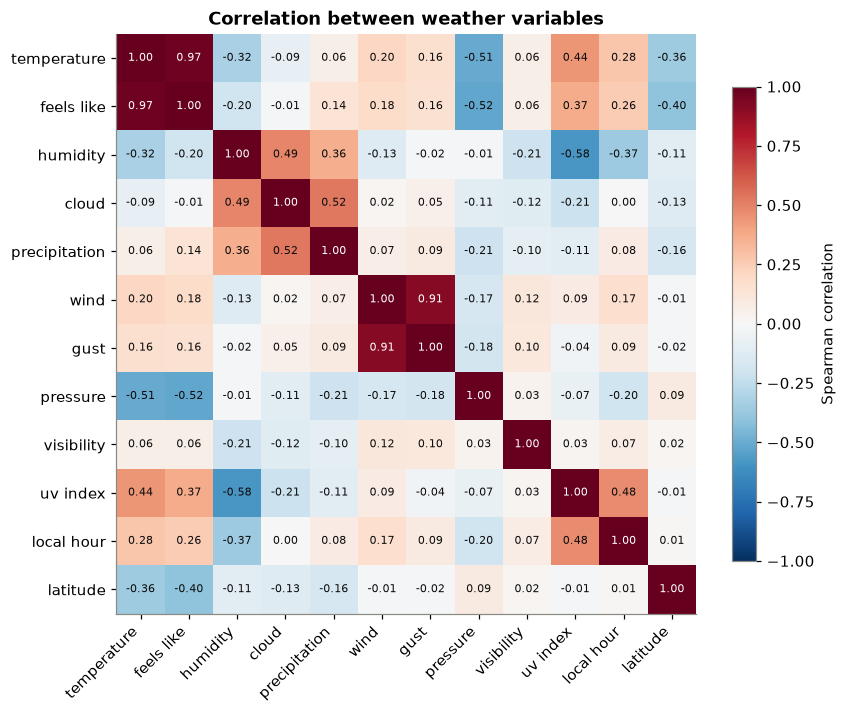

In [17]:
weather_cols = ['temperature_celsius', 'feels_like_celsius', 'humidity', 'cloud', 'precip_mm', 'wind_kph',
                'gust_kph', 'pressure_mb', 'visibility_km', 'uv_index', 'local_hour', 'latitude']
labels = ['temperature', 'feels like', 'humidity', 'cloud', 'precipitation', 'wind', 'gust',
          'pressure', 'visibility', 'uv index', 'local hour', 'latitude']
corr = df[weather_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels)
ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if abs(v) > 0.6 else '#0b0b0b')
fig.colorbar(im, ax=ax, label='Spearman correlation', shrink=0.8)
ax.set_title('Correlation between weather variables')
save(fig, '02_correlation_heatmap.png')
plt.show()

In [18]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename('rho')
print('strongest correlations:')
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(10).round(2))

strongest correlations:
temperature_celsius  feels_like_celsius    0.97
wind_kph             gust_kph              0.91
humidity             uv_index             -0.58
cloud                precip_mm             0.52
feels_like_celsius   pressure_mb          -0.52
temperature_celsius  pressure_mb          -0.51
humidity             cloud                 0.49
uv_index             local_hour            0.48
temperature_celsius  uv_index              0.44
feels_like_celsius   latitude             -0.40
Name: rho, dtype: float64


## 7. Most common weather conditions

saved ../reports/figures/02_conditions_top.png


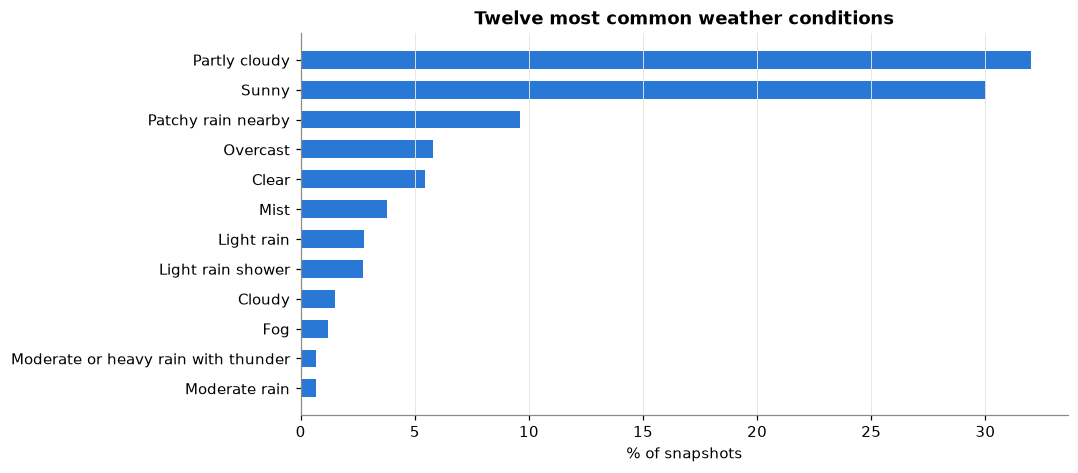

top 12 cover 96.2 % of snapshots


In [19]:
top = df['condition_text'].value_counts().head(12).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.index, top.values / len(df) * 100, color=BLUE, height=0.6)
ax.set_xlabel('% of snapshots')
ax.set_title('Twelve most common weather conditions')
ax.grid(axis='y', visible=False)
save(fig, '02_conditions_top.png')
plt.show()
print('top 12 cover', round(top.sum() / len(df) * 100, 1), '% of snapshots')

## Key findings

All numbers below come from the run above.

1. **Latitude drives temperature and seasonality.** Mean temperature falls with distance from the equator
   (correlation with |latitude| of -0.76), and the seasonal cycle grows with it (correlation 0.85). The warmest
   location is Doha (33.0 C on average), the coldest is Ulaanbaatar (6.0 C).
2. **A global average hides the seasons.** 144 of the 185 locations are in the north. The difference between the
   warmest and coldest month is 16.6 C in the north and 7.0 C in the south, with the two cycles in opposite
   directions. The all-locations line (12.5 C) mostly copies the north. This is why the forecasts are made per city.
3. **The snapshot time drift is visible in the averages.** The July mean fell from 28.5 C (2024) to 27.1 C (2025)
   and 24.7 C (2026) in the north, and also fell in the south. Both hemispheres cooling every year in the same
   month is what earlier snapshots in the day would produce, so this is not read as a climate trend.
4. **The six cities cover very different behaviour.** The standard deviation of daily temperature ranges from
   2.1 C (Singapore, almost no season) to 11.1 C (Moscow). Canberra and Buenos Aires are warmest in February,
   London and Moscow in July, New Delhi in June (before the monsoon).
5. **The hour effect cannot be measured directly.** Within one location-month the snapshot hour varies by only
   0.22 hours (median), while differences between 2024 and 2025 reach 4.9 C (Canberra) and mostly follow the
   direction of the hour shift. `local_hour` goes into every model.
6. **Rain is frequent but light at snapshot time.** 32.5% of snapshots report precipitation, the median amount
   when it rains is 0.10 mm and the 99th percentile is 3.49 mm. New Delhi's monsoon is clear (31 to 46% of
   snapshots wet in July to September, 0 to 7% from October to June) and Singapore is wet in every month.
7. **Some variables are near copies of each other.** Temperature and feels-like (0.97) and wind and gust (0.91)
   carry almost the same information, so only one of each pair should be a model input. Other notable links:
   humidity and UV (-0.58), cloud and precipitation (0.52), temperature and pressure (-0.51).
8. **Conditions:** the 12 most common condition labels cover 96.2% of snapshots.